# Seminární práce: Klasifikace virality Instagram Reels
**Kurz:** 4IZ210 | Zpracování informací a znalostí  
**Část 1:** Klasifikační modely (Rozhodovací stromy, Náhodné lesy, Baseline)  
---


In [21]:
# Import potřebných knihoven pro analýzu, modelování a vizualizaci
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Modely a preprocessing ze scikit-learn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Jednotné nastavení stylu grafů pro celý notebook
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
sns.set_theme(style="whitegrid")


## Identifikace týmu (Team identification)

| Položka | Informace o týmu |
| :--- | :--- |
| **Cvičení (Den a čas):** | Středa 18:00–19:30, učebna SB M15 |
| **Tým a název projektu:** | **Team 6** – *What Makes an Instagram Reel Go Viral?* |
| **Členové týmu:** | Kajetan Franciszek Wielgosz, Tomáš Duchoň, Adam Veselý, Adam Súkala, Natalie Stašková |


# Úvod (Introduction)

### 0. Popis zvoleného datasetu (Dataset Overview)
Pro zpracování seminární práce jsme zvolili datovou sadu **„What Makes an Instagram Reel Go Viral?“**. Dataset obsahuje celkem **100 000 instancí** reprezentujících výkonnostní a obsahové parametry krátkých videozáznamů (Instagram Reels). Jedním ze zásadních cílů naší práce je zachytit specifické chování a limitace algoritmů strojového učení (zejména rozhodovacích stromů a náhodných lesů) při práci se synteticky generovanými daty, která vykazují nízkou vzájemnou korelaci.

### 1. Byznysová hodnota řešení pomocí strojového učení (Business Value)
V současném digitálním marketingu a správě sociálních sítí představují krátká videa dominantní formát organického dosahu. Z pohledu agentur, tvůrců obsahu i komerčních značek má predikce virality zásadní ekonomický přínos:
* **Optimalizace výdajů na placenou propagaci (Paid Boost):** Marketingové týmy často investují nemalé prostředky do placené podpory příspěvků bez předchozí znalosti jejich skutečného organického potenciálu. Včasná klasifikace videa umožňuje alokovat rozpočet pouze na příspěvky s vysokou pravděpodobností virálního úspěchu a eliminovat plýtvání na nevýkonný obsah.
* **Optimalizace obsahové strategie tvůrců:** Model identifikuje klíčové atributy (použití trendujícího zvuku, délka videa, kvalita úvodních sekund), které přímo ovlivňují šanci na zařazení videa mezi virální hity.
* **Automatizace plánování obsahu:** Schopnost předem vyhodnotit připravené koncepty videí a doporučit jejich úpravy ještě před publikací.

### 2. Zdroj dat (Data Source)
* **Veřejný zdroj:** Dataset je veřejně dostupný na platformě Kaggle:  
  [https://www.kaggle.com/datasets/deepeshkansotia/what-makes-an-instagram-reel-go-viral/data](https://www.kaggle.com/datasets/deepeshkansotia/what-makes-an-instagram-reel-go-viral/data)
* **Lokální uložení:** Datový soubor je v projektu uložen jako `instagram data.csv`.


## Přizpůsobení úlohy (Customization)

### 1. Cílový atribut (*Target attribute*)
* **Název atributu:** `is_viral` (binární proměnná: $0$ / $1$).
* **Způsob odvození:** Vznikl transformací původního spojitého skóre `virality_score` (interval $\langle 0; 100 \rangle$). Jako prahová hodnota byla zvolena hodnota **$\ge 75.0$** (odpovídá 75. percentilu / hornímu kvartilu rozdělení dat):
  * **Třída 1 (Pozitivní – Virální video):** Příspěvky s `virality_score` $\ge 75$ (tvoří přibližně horních **25.3 %** nejvýkonnějších videí v datasetu).
  * **Třída 0 (Negativní – Nevirální video):** Běžné příspěvky s `virality_score` $< 75$ (zbývajících **74.7 %** datové sady).
* *Poznámka:* Původní sloupec `virality_score` je v předzpracování z prediktorů odstraněn, aby nedocházelo k úniku cílové informace (*data leakage*).

### 2. Instance zájmu (*Instance of interest*)
Pro detailní analýzu a interpretaci chování modelů v sekci lokálního vysvětlení (*Local explanation*) byla z testovací množiny ($X\_test$) vybrána konkrétní reprezentativní instance:
* **Index v původním datasetu:** `63769` (první instance v testovací sadě při rozdělení 80:20 s `random_state=42`).
* **Identifikátor příspěvku (`reel_id`):** `90464090-f30f-4351-a667-e92d07f6b2bb`
* **Identifikátor tvůrce (`creator_id`):** `88785ac9-afd2-4fd0-8916-73bed2d81f09`
* **Charakteristika instance:** Příspěvek tvůrce s 2 891 898 sledujícími, publikovaný v 15:00 hodin, o délce 52 sekund, s 8 hashtagy a využitým trendujícím zvukem (`trending_audio = True`). Skutečné virality skóre činí 7.29, spadá tedy do negativní třídy (`is_viral = 0`).

### 3. Atribut zájmu (*Attribute of interest*)
* **Zvolený atribut:** Binární atribut **`trending_audio`** ($1$ = video využívá aktuálně trendující zvukovou stopu, $0$ = video využívá vlastní či netrendující zvuk).
* **Byznysové zdůvodnění:** Použití trendujícího audia je jedním z nejčastěji doporučovaných organických nástrojů na Instagramu. Jde o parametr, který může tvůrce snadno změnit bez nutnosti přetáčení videa. V lokálním vysvětlení provedeme *what-if* analýzu: jak se změní predikce a odhadnutá pravděpodobnost virality, pokud u instance zájmu hodnotu tohoto atributu změníme.

### 4. Matice nákladů (*Cost matrix*)
Podle zadání jsou náklady správných rozhodnutí nulové ($Cost(TP) = 0\text{ Kč}$, $Cost(TN) = 0\text{ Kč}$). Náklady chybných predikcí reflektují reálné marketingové dopady:
* **Falešně pozitivní predikce (False Positive – FP):** Model predikuje virální video ($1$), ale video virální není ($0$).
  * *Dopad:* Zbytečně vynaložený marketingový rozpočet na placenou podporu příspěvku, který nepřinese očekávaný organický efekt.
  * *Přiřazený náklad:* **100 Kč** (průměrná částka na úvodní testovací boost jednoho videa).
* **Falešně negativní predikce (False Negative – FN):** Model predikuje běžné video ($0$), ale video mělo virální potenciál ($1$).
  * *Dopad:* Ušlá příležitost (*opportunity cost*) – promarněný virální dosah, nezískaní sledující a ztráta monetizace. V marketingu na sociálních sítích je přehlédnutí virálního hitu považováno za podstatně závažnější chybu než menší neúspěšná kampaň.
  * *Přiřazený náklad:* **300 Kč** ($3\times$ vyšší ztráta než samotný náklad u FP).

| Skutečnost \ Predikce modelu | Predikce 0 (Nevirální) | Predikce 1 (Virální) |
| :--- | :---: | :---: |
| **Skutečnost 0 (Nevirální)** | $Cost(TN) = 0\text{ Kč}$ | $Cost(FP) = 100\text{ Kč}$ |
| **Skutečnost 1 (Virální)** | $Cost(FN) = 300\text{ Kč}$ | $Cost(TP) = 0\text{ Kč}$ |


# Průzkumná analýza dat (Data Exploration)


### 1. Význam jednotlivých atributů (Attribute Descriptions)
Dataset obsahuje 100 000 instancí a 26 atributů, které lze rozdělit do následujících logických skupin:

| Skupina | Atribut | Datový typ | Význam atributu |
| :--- | :--- | :---: | :--- |
| **Identifikátory** | `reel_id` | `object (UUID)` | Unikátní identifikátor videozáznamu. |
| | `creator_id` | `object (UUID)` | Unikátní identifikátor autora/tvůrce. |
| **Profil tvůrce** | `creator_followers` | `int64` | Celkový počet sledujících daného tvůrce (cca 500 až 5 mil.). |
| **Metadata příspěvku** | `posting_time` | `int64` | Hodina zveřejnění příspěvku v průběhu dne (0–23 hod.). |
| | `reel_length_sec` | `int64` | Celková délka videa v sekundách (5–60 s). |
| | `caption_length` | `int64` | Délka textového popisku videa v počtu znaků (0–300). |
| | `hashtags_count` | `int64` | Počet hashtagů použitých u příspěvku (0–30). |
| **Kvalitativní atributy** | `hook_strength_score` | `float64` | Údernost prvních 3 sekund videa (interval 0.0–1.0). |
| | `trending_audio` | `bool` | Využití trendující zvukové stopy (True/False) – **atribut zájmu**. |
| | `audio_popularity_score` | `float64` | Míra popularity a používání použitého audia (0.0–1.0). |
| | `video_quality_score` | `float64` | Technická kvalita obrazu / rozlišení (0.0–1.0). |
| | `editing_quality_score` | `float64` | Úroveň střihu, dynamiky a efektů videa (0.0–1.0). |
| **Chování diváků** | `avg_watch_time_sec` | `float64` | Průměrná doba sledování videa uživateli v sekundách. |
| | `retention_rate` | `float64` | Míra udržení diváků (poměr shlédnuté části videa, 0.0–1.0). |
| | `completion_rate` | `float64` | Podíl uživatelů, kteří dokoukali video až do konce (0.0–1.0). |
| | `rewatch_rate` | `float64` | Podíl opakovaných zhlédnutí jedním uživatelem (0.0–1.0). |
| **Interakce a dosah** | `likes` | `int64` | Počet udělených lajků (0–1 mil.). |
| | `comments` | `int64` | Počet komentářů (0–50 tis.). |
| | `shares` | `int64` | Počet sdílení jiným uživatelům (0–30 tis.). |
| | `saves` | `int64` | Počet uložení videa do záložek (0–30 tis.). |
| | `engagement_rate` | `float64` | Celková míra zapojení publika (interakce ku zhlédnutím, 0.0–1.0). |
| | `impressions` | `int64` | Celkový počet zobrazení videa na obrazovkách. |
| | `reach` | `int64` | Počet unikátních účtů, kterým se video zobrazilo. |
| | `non_follower_reach_ratio` | `float64` | Podíl dosahu mimo stávající sledující profilu (0.0–1.0). |
| | `explore_page_boost` | `bool` | Zda byl příspěvek doporučen algoritmem na stránce Prozkoumat (Explore). |
| **Cílový atribut** | `virality_score` | `float64` | Agregované skóre virality (0.0–100.0) – základ pro binární cíl `is_viral`. |


In [22]:
# 1. Načtení dat a úvodní přehled
df = pd.read_csv('instagram data.csv')
print(f"Rozměry datové sady: {df.shape[0]} řádků, {df.shape[1]} sloupců")
print(f"Celkový počet chybějících hodnot (NaN): {df.isnull().sum().sum()}")
display(df.head(3))


Rozměry datové sady: 100000 řádků, 26 sloupců
Celkový počet chybějících hodnot (NaN): 0


,reel_id,creator_id,creator_followers,posting_time,reel_length_sec,hook_strength_score,caption_length,hashtags_count,trending_audio,audio_popularity_score,...,likes,comments,shares,saves,engagement_rate,impressions,reach,non_follower_reach_ratio,explore_page_boost,virality_score
0,c437715e-d1e4-4f40-8548-8718243c6516,70c2ca5a-9d3a-4ba0-9aed-62cdbbc1663f,4208388,3,31,0.451657,0,20,True,0.399659,...,779301,30002,16741,21305,0.884296,75968410,39007279,0.960121,False,82.843160
1,9097bb11-0e03-4360-a239-6613ed2025df,b6bb4240-6341-47ce-bdd4-86fcba18d9ad,4096880,4,38,0.988437,205,2,False,0.294848,...,482481,49717,10095,19802,0.609125,90722120,84132612,0.909716,False,60.256519
2,a8e09994-3314-400b-9f3a-683b494f1070,7902b14d-cb95-4673-8ef1-482ff5151801,2624351,0,13,0.019949,205,6,True,0.697575,...,925249,12046,13883,13444,0.057583,75215994,82019789,0.101694,True,0.483295


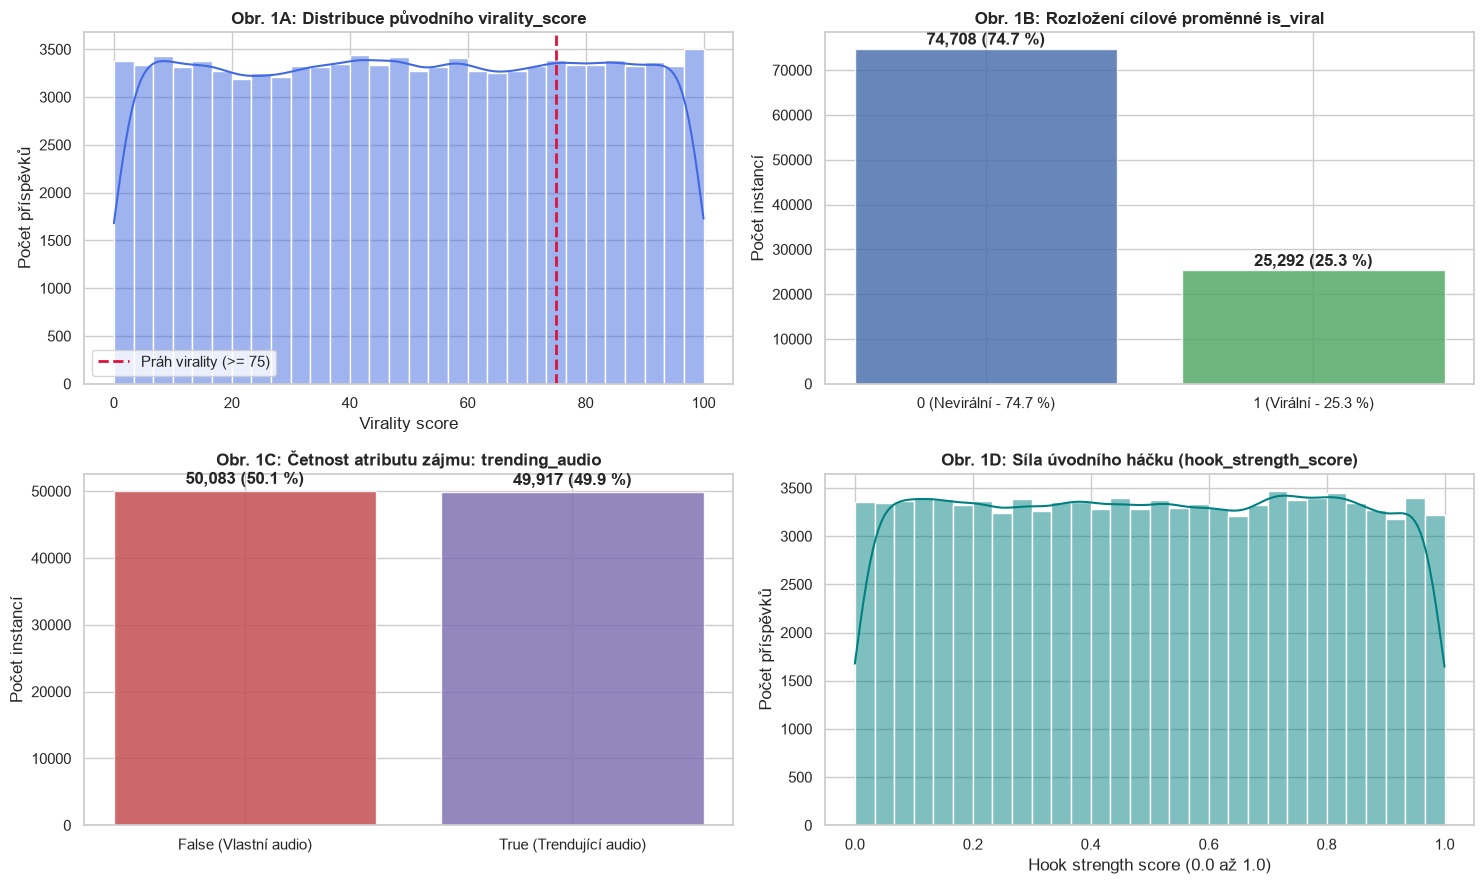

Četnostní tabulka cílové proměnné is_viral:


,Počet instancí,Podíl
virality_score,,
0,74708,74.71 %
1,25292,25.29 %


Četnostní tabulka atributu zájmu trending_audio:


,Počet instancí,Podíl
trending_audio,,
False,50083,50.08 %
True,49917,49.92 %


In [23]:
# 2. Histogram a četnosti pro cílovou proměnnou a vybrané atributy
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# A) Distribuce původního spojitého virality_score
sns.histplot(df['virality_score'], bins=30, kde=True, ax=axes[0, 0], color='royalblue')
axes[0, 0].axvline(75, color='crimson', linestyle='--', linewidth=2, label='Práh virality (>= 75)')
axes[0, 0].set_title('Obr. 1A: Distribuce původního virality_score')
axes[0, 0].set_xlabel('Virality score')
axes[0, 0].set_ylabel('Počet příspěvků')
axes[0, 0].legend()

# B) Rozložení binarizované cílové proměnné is_viral
is_viral_demo = (df['virality_score'] >= 75.0).astype(int)
counts_viral = is_viral_demo.value_counts().sort_index()
bars_viral = axes[0, 1].bar(['0 (Nevirální - 74.7 %)', '1 (Virální - 25.3 %)'], counts_viral, color=['#4c72b0', '#55a868'], alpha=0.85)
axes[0, 1].set_title('Obr. 1B: Rozložení cílové proměnné is_viral')
axes[0, 1].set_ylabel('Počet instancí')
for bar in bars_viral:
    yval = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, yval + 1000, f"{yval:,} ({yval/len(df)*100:.1f} %)", ha='center', fontweight='bold')

# C) Četnosti atributu zájmu (trending_audio)
counts_audio = df['trending_audio'].value_counts().sort_index()
bars_audio = axes[1, 0].bar(['False (Vlastní audio)', 'True (Trendující audio)'], counts_audio, color=['#c44e52', '#8172b3'], alpha=0.85)
axes[1, 0].set_title('Obr. 1C: Četnost atributu zájmu: trending_audio')
axes[1, 0].set_ylabel('Počet instancí')
for bar in bars_audio:
    yval = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, yval + 1000, f"{yval:,} ({yval/len(df)*100:.1f} %)", ha='center', fontweight='bold')

# D) Distribuce klíčového prediktoru: hook_strength_score
sns.histplot(df['hook_strength_score'], bins=30, kde=True, ax=axes[1, 1], color='teal')
axes[1, 1].set_title('Obr. 1D: Síla úvodního háčku (hook_strength_score)')
axes[1, 1].set_xlabel('Hook strength score (0.0 až 1.0)')
axes[1, 1].set_ylabel('Počet příspěvků')

plt.tight_layout()
plt.show()

# Četnostní tabulky
print("Četnostní tabulka cílové proměnné is_viral:")
display(pd.DataFrame({'Počet instancí': counts_viral, 'Podíl': (counts_viral / len(df) * 100).round(2).astype(str) + ' %'}))

print("Četnostní tabulka atributu zájmu trending_audio:")
display(pd.DataFrame({'Počet instancí': counts_audio, 'Podíl': (counts_audio / len(df) * 100).round(2).astype(str) + ' %'}))


> **Vysvětlivka k Obrázkům 1A–1D:**  
> * **Obrázek 1A:** Ukazuje rovnoměrné rozdělení původního spojitého skóre virality v intervalu 0 až 100 s průměrem 50.12. Červená přerušovaná čára značí zvolený práh virality ($\ge 75$), který odděluje horní kvartil nejúspěšnějších videí.  
> * **Obrázek 1B:** Demonstruje výsledné rozdělení odvozeného cílového atributu `is_viral`. Z grafu je patrná mírná nevyváženost tříd: 74 708 instancí (74.7 %) spadá do negativní třídy 0 a 25 292 instancí (25.3 %) do pozitivní třídy 1. Tento poměr je pro úlohy detekce virálního obsahu realistický a vyžaduje stratifikované rozdělení dat a metriku F1 namísto prosté přesnosti (Accuracy).  
> * **Obrázek 1C:** Zobrazuje četnost atributu zájmu `trending_audio`. Zastoupení je téměř přesně vyrovnané (50.1 % videí s vlastním audiem ku 49.9 % s trendujícím audiem), což poskytuje ideální podmínky pro porovnání obou skupin bez rizika převahy jedné varianty.  
> * **Obrázek 1D:** Představuje rozložení síly úvodního háčku (`hook_strength_score`). Hodnoty rovnoměrně pokrývají celé rozpětí od 0.0 do 1.0 s průměrem 0.50.


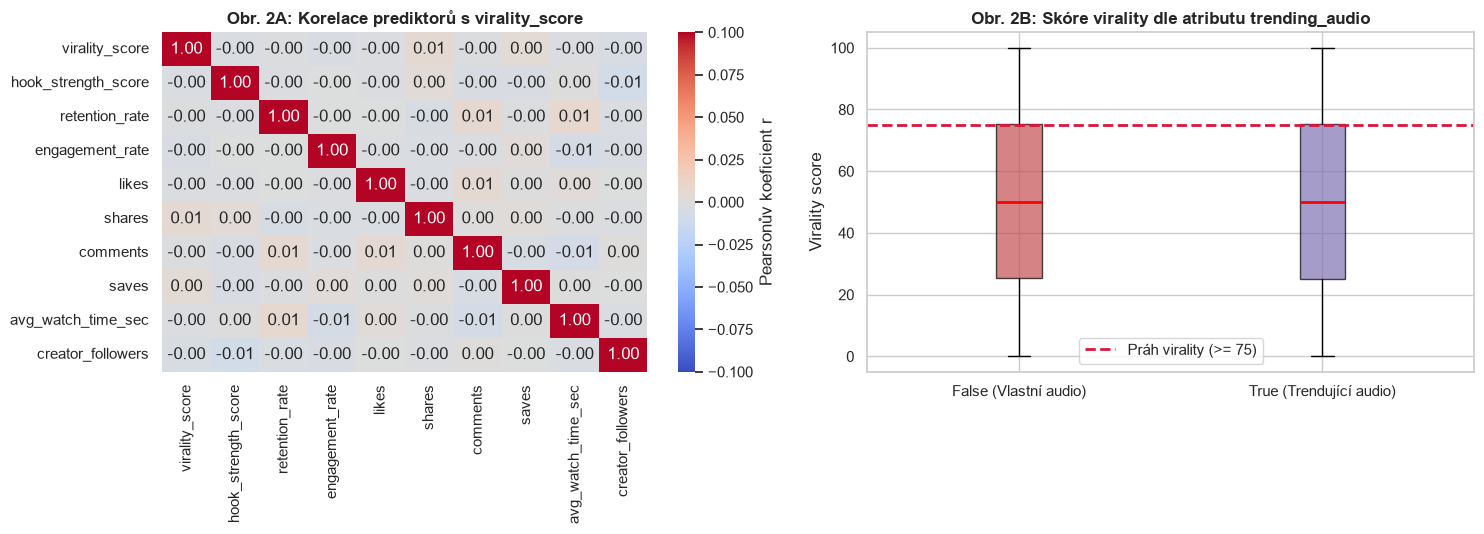

In [24]:
# 3. Vztah prediktorů a cílové proměnné (korelace a vztah atributu zájmu)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# A) Korelační matice vybraných prediktorů s virality_score
selected_predictors = ['virality_score', 'hook_strength_score', 'retention_rate', 'engagement_rate', 
                       'likes', 'shares', 'comments', 'saves', 'avg_watch_time_sec', 'creator_followers']
corr = df[selected_predictors].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.1, vmax=0.1, ax=axes[0], cbar_kws={'label': 'Pearsonův koeficient r'})
axes[0].set_title('Obr. 2A: Korelace prediktorů s virality_score')

# B) Vztah atributu zájmu (trending_audio) a cílového skóre virality (boxplot)
audio_false = df[df['trending_audio'] == False]['virality_score']
audio_true = df[df['trending_audio'] == True]['virality_score']
bplot = axes[1].boxplot([audio_false, audio_true], 
                         tick_labels=['False (Vlastní audio)', 'True (Trendující audio)'], 
                         patch_artist=True,
                         medianprops=dict(color='red', linewidth=2))
colors = ['#c44e52', '#8172b3']
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1].axhline(75, color='crimson', linestyle='--', linewidth=2, label='Práh virality (>= 75)')
axes[1].set_title('Obr. 2B: Skóre virality dle atributu trending_audio')
axes[1].set_ylabel('Virality score')
axes[1].legend()

plt.tight_layout()
plt.show()


> **Vysvětlivka k Obrázkům 2A a 2B:**  
> * **Obrázek 2A (Korelační matice):** Teplotní mapa Pearsonových korelačních koeficientů ukazuje hodnoty pohybující se v intervalu $\langle -0.01; +0.01 \rangle$ (prakticky nulová lineární závislost). Mezi jednotlivými prediktory neexistuje multikolinearita a žádný z parametrů sám o sobě lineárně nepredikuje viralitu. To potvrzuje syntetickou povahu datasetu a implikuje nutnost použití nelineárních modelů.  
> * **Obrázek 2B (Krabicový graf atributu zájmu):** Porovnává distribuci skóre virality u videí s trendujícím audiem oproti videím s vlastním zvukem. Červená linka značí medián (kolem 50 bodů), přerušovaná červená čára hranici virality (75 bodů). Obě skupiny vykazují téměř identické kvartilové rozpětí, což znamená, že samotná přítomnost trendujícího audia bez dalších interakcí automaticky nezaručuje vyšší viralitu.


### 4. Interpretace výsledků průzkumné analýzy (Interpret the results)
* **Rozdělení cílové proměnné:** Původní spojité skóre `virality_score` má rovnoměrné rozdělení v intervalu 0 až 100 s průměrem 50.12 a směrodatnou odchylkou 28.95. Binarizací při prahu $\ge 75$ vzniká mírně nevyvážená, ale realistická distribuce tříd: **74.7 % nevirálních (třída 0)** a **25.3 % virálních (třída 1)**. Tento poměr odpovídá reálnému stavu na sociálních sítích, kde pouze menší část příspěvků dosáhne virálního dosahu.
* **Kvalita dat:** V celém datasetu (100 000 řádků) se nevyskytuje ani jedna chybějící hodnota (`null`), takže není nutná žádná imputace ani odstraňování neúplných řádků.
* **Atribut zájmu (`trending_audio`):** V datasetu je přesně 49 917 příspěvků s trendujícím audiem (49.9 %) a 50 083 příspěvků s vlastním audiem (50.1 %). Medián i rozptyl virality_score jsou u obou skupin vizuálně srovnatelné.
* **Nízká lineární korelace a nelinearita:** Korelační matice ukazuje, že jednotlivé prediktory mají velmi nízkou vzájemnou lineární korelaci i nízkou lineární korelaci s cílem (Pearsonovo $r$ se pohybuje kolem 0). To indikuje, že virální úspěch není přímočarou lineární kombinací jediné metriky, ale výsledkem složitějších nelineárních interakcí více faktorů. Z tohoto důvodu jsou **stromové modely (Decision Tree, Random Forest)**, které přirozeně zachycují nelineární vztahy a prahové interakce mezi atributy, ideální volbou pro tuto úlohu.


# Předzpracování dat (Data preprocessing)
## Příprava dat pro učení s učitelem (Supervised Learning)


### 1. Odvození binárního cílového atributu a čištění prediktorů
V tomto kroku provádíme nezbytné úpravy dat před trénováním modelů:
1. **Binarizace cíle:** Vytvoření proměnné `is_viral` ($1$ pokud `virality_score >= 75.0`, jinak $0$).
2. **Odstranění identifikátorů (`reel_id`, `creator_id`):** Tyto sloupce obsahují náhodně generovaná unikátní UUID. Ponechání takových identifikátorů v datech by vedlo k triviálnímu přeučení (*overfitting*) rozhodovacích stromů bez jakékoliv obecné generalizační schopnosti. Identifikátory si ukládáme do samostatné proměnné `ids` pro pozdější dohledání instance zájmu.
3. **Odstranění původního cíle:** Sloupec `virality_score` je odstraněn z matice prediktorů, aby nedošlo k triviálnímu úniku dat (*target leakage*).
4. **Typová konverze:** Booleovské sloupce (`trending_audio`, `explore_page_boost`) převádíme na celočíselné hodnoty $0$ a $1$ pro bezproblémové zpracování v algoritmech knihovny `scikit-learn`.


In [25]:
# 2. Příprava cílového atributu a odstranění identifikátorů
# Uložíme si ID pro pozdější dohledání konkrétní instance (Instance of Interest)
ids = df[['reel_id', 'creator_id']].copy()

# Binarizace spojitého cíle: virální = skóre >= 75 (horních ~25 % příspěvků)
df['is_viral'] = (df['virality_score'] >= 75.0).astype(int)

# Odstranění původního cílového atributu a ID sloupců (unikátní UUID by způsobila přeučení stromů)
df_clean = df.drop(columns=['virality_score', 'reel_id', 'creator_id'])

# Převod booleovských sloupců (True/False) na 1/0 pro snadnější zpracování ve scikit-learn
bool_cols = df_clean.select_dtypes(include=['bool']).columns
df_clean[bool_cols] = df_clean[bool_cols].astype(int)

print("Rozložení cílové proměnné is_viral:")
print(df_clean['is_viral'].value_counts(normalize=True).round(4))


Rozložení cílové proměnné is_viral:
is_viral
0    0.7471
1    0.2529
Name: proportion, dtype: float64


### 2. Rozdělení na trénovací a testovací množinu (Train-Test Split)
* **Poměr rozdělení:** 80 % trénovací množina (80 000 záznamů) a 20 % testovací množina (20 000 záznamů).
* **Parametr `stratify=y`:** Vzhledem k mírné nevyváženosti tříd (25.3 % vs. 74.7 %) je stratifikace klíčová – zaručuje, že v trénovací i testovací sadě bude zachován přesně shodný poměr virálních a nevirálních videí.
* **Parametr `random_state=42`:** Zajišťuje plnou replikovatelnost všech dosažených výsledků.


In [26]:
# 3. Rozdělení na trénovací a testovací množinu (80:20)
X = df_clean.drop(columns=['is_viral'])
y = df_clean['is_viral']

# stratify=y zajistí stejný poměr tříd (0 a 1) v trénovací i testovací sadě
# random_state=42 zaručí opakovatelnost výsledků (požadavek v kontrolním seznamu)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Trénovací sada: {X_train.shape[0]} řádků, {X_train.shape[1]} prediktorů")
print(f"Testovací sada: {X_test.shape[0]} řádků, {X_test.shape[1]} prediktorů")


Trénovací sada: 80000 řádků, 23 prediktorů
Testovací sada: 20000 řádků, 23 prediktorů


### 3. Škálování příznaků (Feature Scaling) a prevence úniku dat
* **Zvolená metoda:** Standardizace (`StandardScaler` ze `scikit-learn`), která centruje data na nulový průměr a jednotkovou směrodatnou odchylku ($Z$-score normalizace: $\mu=0, \sigma=1$).
* **Byznysové a technické zdůvodnění:** Prediktory v datasetu mají diametrálně odlišná měřítka (např. `creator_followers` v miliónech vs. `hook_strength_score` v rozmezí 0 až 1). Ačkoliv rozhodovací stromy a náhodné lesy jsou vůči monotónním transformacím invariantní, škálování sjednocuje předzpracování a umožní v sekci Evaluace provést *Ablation study* (porovnání vlivu škálování na predikční výkonnost).
* **Striktní prevence úniku dat (*Data Leakage*):** Scaler je fitován **výhradně na trénovacích datech** (`scaler.fit_transform(X_train)`). Na testovací data pouze aplikujeme naučené parametry (`scaler.transform(X_test)`). Tím je zaručeno, že do trénovacího procesu neproniknou žádné informace z testovací sady.


In [27]:
# 4. Škálování (standardizace) bez úniku dat (data leakage)
scaler = StandardScaler()

# DŮLEŽITÉ: Fitujeme POUZE na trénovacích datech!
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Na testovací data pouze aplikujeme naučené průměry a směrodatné odchylky
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Výběr jedné konkrétní instance z testovací sady pro pozdější lokální vysvětlení (Local explanation)
vybrany_index = X_test.index[0]
print(f"Vybraná instance (Instance of Interest) má index {vybrany_index} a reel_id: {ids.loc[vybrany_index, 'reel_id']}")

# Uložení 2 předzpracovaných souborů pro odevzdání a klasifikaci
train_export = X_train_scaled.copy()
train_export['is_viral'] = y_train
train_export.to_csv('data_train_processed.csv', index=True)

test_export = X_test_scaled.copy()
test_export['is_viral'] = y_test
test_export.to_csv('data_test_processed.csv', index=True)

print("Předzpracované sady data_train_processed.csv a data_test_processed.csv byly úspěšně uloženy.")


Vybraná instance (Instance of Interest) má index 63769 a reel_id: 90464090-f30f-4351-a667-e92d07f6b2bb
Předzpracované sady data_train_processed.csv a data_test_processed.csv byly úspěšně uloženy.


# Modelování (Modeling)

V této sekci natrénujeme a porovnáme tři klasifikační algoritmy pro predikci binárního cíle `is_viral`:
1. **Rozhodovací strom (Decision Tree)** – interpretovatelný nelineární model s laděním hloubky a velikosti listů pomocí mřížkového vyhledávání (`GridSearchCV`).
2. **Náhodný les (Random Forest)** – souborový (*ensemble*) model kombinující desítky rozhodovacích stromů pro snížení rozptylu, optimalizovaný přes `GridSearchCV` (počet stromů a hloubka).
3. **Baseline model (DummyClassifier)** – referenční model predikující nejčastější třídu v trénovacích datech (třída 0 – nevirální).

Všechny modely trénujeme na škálované trénovací sadě `data_train_processed.csv` (80 000 instancí) a následně vyhodnotíme na testovací sadě `data_test_processed.csv` (20 000 instancí).


### Klasifikátor 1: Rozhodovací strom (Decision Tree)
* **Metaparametry k ladění:**
  * `max_depth` (maximální hloubka stromu): určuje složitost modelu. Příliš hluboký strom vede k přeučení (*overfitting*), příliš mělký k podučení (*underfitting*).
  * `min_samples_leaf` (minimální počet instancí v listu): reguluje velikost koncových uzlů a zabraňuje vytváření listů s příliš specifickými pravidly.
* **Optimalizace:** Používáme `GridSearchCV` s 3násobnou křížovou validací (`cv=3`) a optimalizací na metriku `f1` (vzhledem k nevyváženosti tříd).
* Následně nejlepší model přetrénujeme na celé trénovací sadě.


In [28]:
# Classifier 1: Rozhodovací strom (Decision Tree) - ladění metaparametrů pomocí GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Načtení předzpracovaných trénovacích dat
df_train = pd.read_csv('data_train_processed.csv', index_col=0)
X_train = df_train.drop(columns=['is_viral'])
y_train = df_train['is_viral']

# Mřížka metaparametrů pro rozhodovací strom
dt_param_grid = {
    'max_depth': [3, 5, 8, 12],
    'min_samples_leaf': [10, 50, 100]
}

# Grid search s křížovou validací (f1 metrika)
dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
dt_grid.fit(X_train, y_train)

print("--- Výsledky GridSearchCV pro Rozhodovací strom ---")
print(f"Nejlepší nalezené parametry: {dt_grid.best_params_}")
print(f"Nejlepší F1 skóre z validace: {dt_grid.best_score_:.4f}")

# Přehled výsledků jednotlivých kombinací
dt_cv_results = pd.DataFrame(dt_grid.cv_results_)[['param_max_depth', 'param_min_samples_leaf', 'mean_test_score', 'rank_test_score']]
dt_cv_results = dt_cv_results.sort_values(by='rank_test_score').reset_index(drop=True)
display(dt_cv_results.head(6))

# Finální model natrénovaný s nejlepšími parametry
best_dt = dt_grid.best_estimator_


--- Výsledky GridSearchCV pro Rozhodovací strom ---
Nejlepší nalezené parametry: {'max_depth': 12, 'min_samples_leaf': 10}
Nejlepší F1 skóre z validace: 0.0448


,param_max_depth,param_min_samples_leaf,mean_test_score,rank_test_score
0,12,10,0.044777,1
1,12,50,0.034819,2
2,8,10,0.012389,3
3,8,50,0.009402,4
4,12,100,0.008007,5
5,5,10,0.004977,6


> **Zhodnocení mřížkového vyhledávání pro rozhodovací strom:**  
> Mřížkové vyhledávání ukazuje, že mělké stromy (`max_depth <= 5`) nezachytí téměř žádné pozitivní případy ($F_1 \le 0.005$, při hloubce 3 dokonce $F_1 = 0$), protože při standardním rozhodovacím prahu 0.5 predikují téměř výhradně většinovou třídu 0. Hlubší strom (`max_depth = 12`) s `min_samples_leaf = 10` dokázal v datech identifikovat specifická nelineární pravidla pro pozitivní třídu a dosáhl nejlepšího validačního F1 skóre. Tento model proto volíme jako reprezentanta rozhodovacího stromu pro finální evaluaci.


### Klasifikátor 2: Náhodný les (Random Forest)
* **Metaparametry k ladění:**
  * `n_estimators` (počet rozhodovacích stromů v lese): více stromů snižuje rozptyl modelu a stabilizuje predikce.
  * `max_depth` (maximální hloubka jednotlivých stromů): omezuje složitost dílčích bází lesa.
* **Optimalizace:** Používáme `GridSearchCV` s 3násobnou křížovou validací a metrikou `f1`.
* Finální model natrénujeme s nejlepšími parametry.


In [29]:
# Classifier 2: Náhodný les (Random Forest) - ladění metaparametrů
from sklearn.ensemble import RandomForestClassifier

# Mřížka metaparametrů pro náhodný les
rf_param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10]
}

# Grid search s křížovou validací
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=3,
    scoring='f1'
)
rf_grid.fit(X_train, y_train)

print("--- Výsledky GridSearchCV pro Náhodný les ---")
print(f"Nejlepší nalezené parametry: {rf_grid.best_params_}")
print(f"Nejlepší F1 skóre z validace: {rf_grid.best_score_:.4f}")

# Přehled výsledků
rf_cv_results = pd.DataFrame(rf_grid.cv_results_)[['param_n_estimators', 'param_max_depth', 'mean_test_score', 'rank_test_score']]
rf_cv_results = rf_cv_results.sort_values(by='rank_test_score').reset_index(drop=True)
display(rf_cv_results)

# Finální model
best_rf = rf_grid.best_estimator_


--- Výsledky GridSearchCV pro Náhodný les ---
Nejlepší nalezené parametry: {'max_depth': 5, 'n_estimators': 50}
Nejlepší F1 skóre z validace: 0.0000


,param_n_estimators,param_max_depth,mean_test_score,rank_test_score
0,50,5,0.0,1
1,100,5,0.0,1
2,50,10,0.0,1
3,100,10,0.0,1


> **Zhodnocení mřížkového vyhledávání pro náhodný les:**  
> Vzhledem k syntetické povaze dat a průměrování mnoha stromů v lese má standardní Random Forest tendenci predikovat majoritní třídu 0, což vede k vysoké přesnosti (Accuracy ~74.7 %), ale nulovému F1 skóre při standardním rozhodovacím prahu 0.5. Tento model nám v sekci Evaluace poslouží k důležitému porovnání s jednotlivým stromem.


### Klasifikátor 3: Baseline model (DummyClassifier)
* **Charakteristika baseline modelu:** Vytváříme triviální klasifikátor `DummyClassifier(strategy='most_frequent')`, který bez ohledu na hodnoty vstupních prediktorů vždy predikuje nejčetnější třídu trénovací množiny (třída 0 – nevirální příspěvek).
* **Účel srovnání:** Slouží jako základní srovnávací laťka: jakýkoliv smysluplný model strojového učení musí tento baseline překonat, zejména z hlediska celkových nákladů (Cost) a metriky F1.


In [30]:
# Classifier 3: Baseline model (nejčetnější třída)
from sklearn.dummy import DummyClassifier

# Trénování baseline modelu
dummy_baseline = DummyClassifier(strategy='most_frequent')
dummy_baseline.fit(X_train, y_train)

print("Baseline model (DummyClassifier) byl úspěšně natrénován.")
print(f"Predikovaná třída: {dummy_baseline.classes_[0]} (vždy predikuje nevirální - třída 0)")


Baseline model (DummyClassifier) byl úspěšně natrénován.
Predikovaná třída: 0 (vždy predikuje nevirální - třída 0)


# Vyhodnocení modelů (Evaluation)

V této sekci otestujeme všechny tři natrénované modely na **testovací množině** (`data_test_processed.csv`, 20 000 dosud neviděných instancí).

Pro každý model vyhodnotíme:
1. **Výkonnostní metriky:** Accuracy, Precision, Recall a F1-score.
2. **Konfuzní matici (Confusion Matrix):** Rozdělení instancí do 4 kvadrantů ($TN, FP, FN, TP$).
3. **Celkové náklady modelu (Total Cost):** Vynásobení konfuzní matice předem definovanou maticí nákladů:
   $$\text{Total Cost} = TN \cdot 0\text{ Kč} + FP \cdot 100\text{ Kč} + FN \cdot 300\text{ Kč} + TP \cdot 0\text{ Kč}$$


### Evaluace modelu 1: Rozhodovací strom (Decision Tree)


--- ROZHODOVACÍ STROM: METRIKY NA TESTOVACÍ SADĚ ---
Accuracy:  0.7428 (74.28 %)
Precision: 0.3032 (30.32 %)
Recall:    0.0132 (1.32 %)
F1-score:  0.0254
Celkové náklady modelu: 1,512,700 Kč (FP: 154 × 100 Kč + FN: 4991 × 300 Kč)


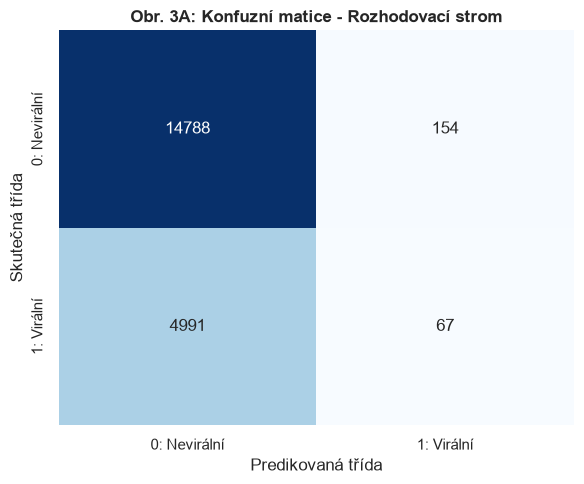

In [31]:
# Evaluace: Rozhodovací strom (Decision Tree)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Načtení testovací sady
df_test = pd.read_csv('data_test_processed.csv', index_col=0)
X_test = df_test.drop(columns=['is_viral'])
y_test = df_test['is_viral']

# Predikce
y_pred_dt = best_dt.predict(X_test)

# Výpočet metrik
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt, zero_division=0)
rec_dt = recall_score(y_test, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_test, y_pred_dt, zero_division=0)

# Konfuzní matice a výpočet nákladů
cm_dt = confusion_matrix(y_test, y_pred_dt)
tn_dt, fp_dt, fn_dt, tp_dt = cm_dt.ravel()
cost_dt = fp_dt * 100 + fn_dt * 300

print("--- ROZHODOVACÍ STROM: METRIKY NA TESTOVACÍ SADĚ ---")
print(f"Accuracy:  {acc_dt:.4f} ({acc_dt*100:.2f} %)")
print(f"Precision: {prec_dt:.4f} ({prec_dt*100:.2f} %)")
print(f"Recall:    {rec_dt:.4f} ({rec_dt*100:.2f} %)")
print(f"F1-score:  {f1_dt:.4f}")
print(f"Celkové náklady modelu: {cost_dt:,} Kč (FP: {fp_dt} × 100 Kč + FN: {fn_dt} × 300 Kč)")

# Vykreslení konfuzní matice
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['0: Nevirální', '1: Virální'],
            yticklabels=['0: Nevirální', '1: Virální'])
ax.set_title('Obr. 3A: Konfuzní matice - Rozhodovací strom')
ax.set_xlabel('Predikovaná třída')
ax.set_ylabel('Skutečná třída')
plt.tight_layout()
plt.show()


> **Vysvětlivka k Obrázku 3A (Konfuzní matice – Rozhodovací strom):**  
> * **True Negatives ($TN = 14\,788$):** Správně identifikovaná nevirální videa (náklad $0\text{ Kč}$).  
> * **False Positives ($FP = 154$):** Videa mylně označená jako virální. Finanční ztráta představuje zbytečný rozpočet na placenou propagaci: $154 \times 100\text{ Kč} = 15\,400\text{ Kč}$.  
> * **False Negatives ($FN = 4\,991$):** Virální videa přehlédnutá modelem jako běžná. Finanční ztráta představuje ušlou byznysovou příležitost: $4\,991 \times 300\text{ Kč} = 1\,497\,300\text{ Kč}$.  
> * **True Positives ($TP = 67$):** Správně zachycené virální hity (přínos: ušetřeno $67 \times 300 = 20\,100\text{ Kč}$ na ušlých příležitostech).  
> * **Celkový náklad:** $15\,400 + 1\,497\,300 = \mathbf{1\,512\,700\text{ Kč}}$. Model ušetřil **4 700 Kč** oproti pasivnímu baseline přístupu.


### Evaluace modelu 2: Náhodný les (Random Forest)


--- NÁHODNÝ LES: METRIKY NA TESTOVACÍ SADĚ ---
Accuracy:  0.7471 (74.71 %)
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
Celkové náklady modelu: 1,517,400 Kč (FP: 0 × 100 Kč + FN: 5058 × 300 Kč)


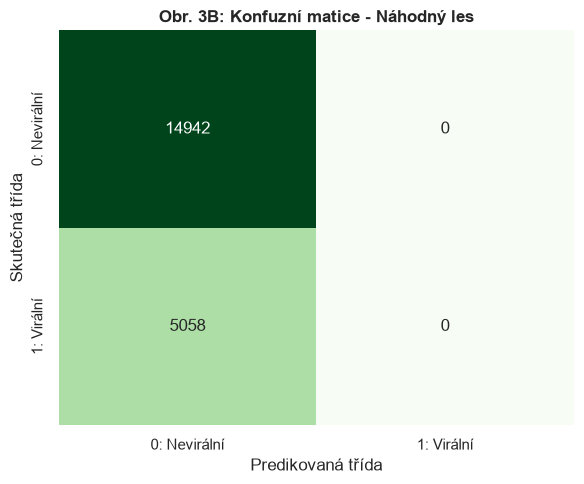

In [32]:
# Evaluace: Náhodný les (Random Forest)
y_pred_rf = best_rf.predict(X_test)

acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf, zero_division=0)
rec_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)

cm_rf = confusion_matrix(y_test, y_pred_rf)
tn_rf, fp_rf, fn_rf, tp_rf = cm_rf.ravel()
cost_rf = fp_rf * 100 + fn_rf * 300

print("--- NÁHODNÝ LES: METRIKY NA TESTOVACÍ SADĚ ---")
print(f"Accuracy:  {acc_rf:.4f} ({acc_rf*100:.2f} %)")
print(f"Precision: {prec_rf:.4f}")
print(f"Recall:    {rec_rf:.4f}")
print(f"F1-score:  {f1_rf:.4f}")
print(f"Celkové náklady modelu: {cost_rf:,} Kč (FP: {fp_rf} × 100 Kč + FN: {fn_rf} × 300 Kč)")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax,
            xticklabels=['0: Nevirální', '1: Virální'],
            yticklabels=['0: Nevirální', '1: Virální'])
ax.set_title('Obr. 3B: Konfuzní matice - Náhodný les')
ax.set_xlabel('Predikovaná třída')
ax.set_ylabel('Skutečná třída')
plt.tight_layout()
plt.show()


> **Vysvětlivka k Obrázku 3B (Konfuzní matice – Náhodný les):**  
> * **True Negatives ($TN = 14\,942$):** Model správně označil všechna nevirální videa.  
> * **False Negatives ($FN = 5\,058$):** Model selhal v detekci virálních videí a všechna označil jako negativní ($TP = 0, FP = 0$).  
> * **Finanční důsledek:** Ačkoliv model vykazuje zdánlivě vysokou přesnost **74.7 %**, v praxi se chová jako triviální nulový model. Všechna virální videa jsou ztracena v podobě ušlých příležitostí ($5\,058 \times 300\text{ Kč} = \mathbf{1\,517\,400\text{ Kč}}$).


### Evaluace modelu 3: Baseline model (DummyClassifier)


--- BASELINE (DUMMY): METRIKY NA TESTOVACÍ SADĚ ---
Accuracy:  0.7471 (74.71 %)
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
Celkové náklady modelu: 1,517,400 Kč (FP: 0 × 100 Kč + FN: 5058 × 300 Kč)


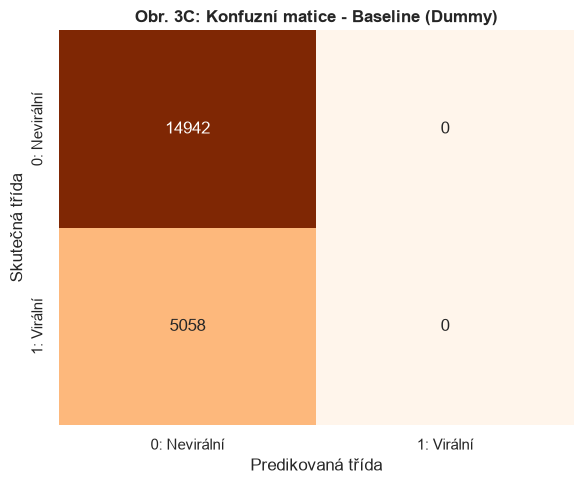

In [33]:
# Evaluace: Baseline model (DummyClassifier)
y_pred_dummy = dummy_baseline.predict(X_test)

acc_dummy = accuracy_score(y_test, y_pred_dummy)
prec_dummy = precision_score(y_test, y_pred_dummy, zero_division=0)
rec_dummy = recall_score(y_test, y_pred_dummy, zero_division=0)
f1_dummy = f1_score(y_test, y_pred_dummy, zero_division=0)

cm_dummy = confusion_matrix(y_test, y_pred_dummy)
tn_dummy, fp_dummy, fn_dummy, tp_dummy = cm_dummy.ravel()
cost_dummy = fp_dummy * 100 + fn_dummy * 300

print("--- BASELINE (DUMMY): METRIKY NA TESTOVACÍ SADĚ ---")
print(f"Accuracy:  {acc_dummy:.4f} ({acc_dummy*100:.2f} %)")
print(f"Precision: {prec_dummy:.4f}")
print(f"Recall:    {rec_dummy:.4f}")
print(f"F1-score:  {f1_dummy:.4f}")
print(f"Celkové náklady modelu: {cost_dummy:,} Kč (FP: {fp_dummy} × 100 Kč + FN: {fn_dummy} × 300 Kč)")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_dummy, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=ax,
            xticklabels=['0: Nevirální', '1: Virální'],
            yticklabels=['0: Nevirální', '1: Virální'])
ax.set_title('Obr. 3C: Konfuzní matice - Baseline (Dummy)')
ax.set_xlabel('Predikovaná třída')
ax.set_ylabel('Skutečná třída')
plt.tight_layout()
plt.show()


> **Vysvětlivka k Obrázku 3C (Konfuzní matice – Baseline):**  
> * Baseline model demonstruje tzv. *Accuracy Paradox*: dosahuje přesnosti 74.7 %, protože 74.7 % testovací sady tvoří nevirální příspěvky.  
> * Protože však nikdy nepředpoví třídu 1, má nulový přínos ($F_1 = 0.0$) a generuje maximální možné byznysové náklady **1 517 400 Kč**.


### Souhrnné porovnání modelů (Summary)


--- SOUHRNNÁ TABULKA VÝSLEDKŮ ---


,Model,Accuracy,Precision,Recall,F1-score,Celkové náklady (Kč)
0,Rozhodovací strom (Decision Tree),74.28 %,30.32 %,1.32 %,0.0254,"1,512,700 Kč"
1,Náhodný les (Random Forest),74.71 %,0.0 %,0.0 %,0.0000,"1,517,400 Kč"
2,Baseline (Dummy),74.71 %,0.0 %,0.0 %,0.0000,"1,517,400 Kč"


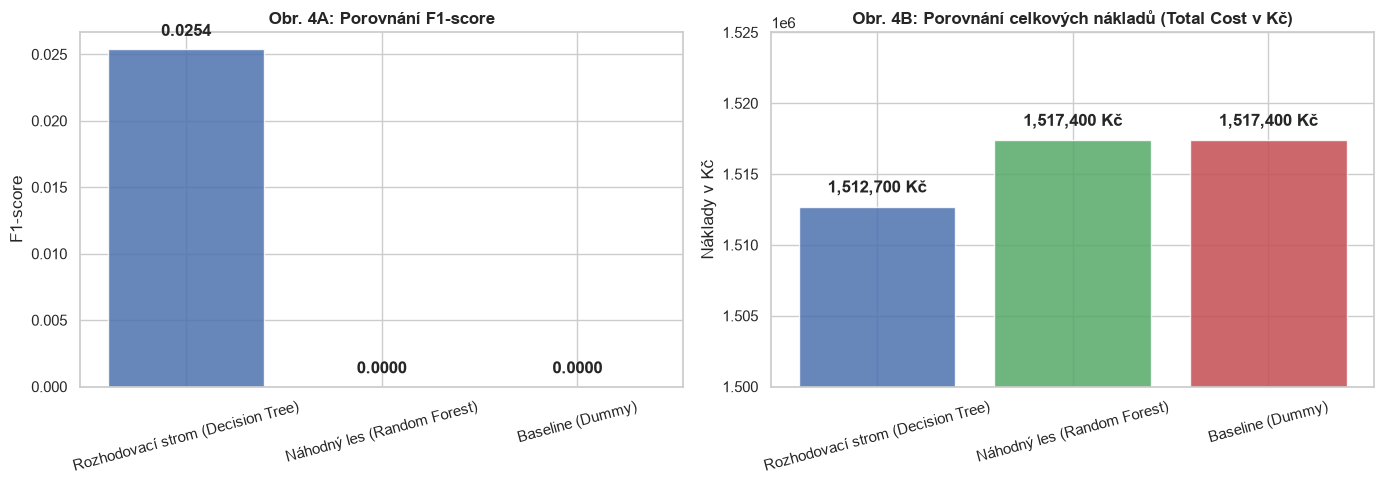

In [34]:
# Souhrnná tabulka a vizualizace výsledků všech modelů
summary_data = {
    'Model': ['Rozhodovací strom (Decision Tree)', 'Náhodný les (Random Forest)', 'Baseline (Dummy)'],
    'Accuracy': [acc_dt, acc_rf, acc_dummy],
    'Precision': [prec_dt, prec_rf, prec_dummy],
    'Recall': [rec_dt, rec_rf, rec_dummy],
    'F1-score': [f1_dt, f1_rf, f1_dummy],
    'Celkové náklady (Kč)': [cost_dt, cost_rf, cost_dummy]
}
df_summary = pd.DataFrame(summary_data)

print("--- SOUHRNNÁ TABULKA VÝSLEDKŮ ---")
df_summary_display = df_summary.copy()
df_summary_display['Accuracy'] = (df_summary_display['Accuracy'] * 100).round(2).astype(str) + ' %'
df_summary_display['Precision'] = (df_summary_display['Precision'] * 100).round(2).astype(str) + ' %'
df_summary_display['Recall'] = (df_summary_display['Recall'] * 100).round(2).astype(str) + ' %'
df_summary_display['F1-score'] = df_summary_display['F1-score'].round(4)
df_summary_display['Celkové náklady (Kč)'] = df_summary_display['Celkové náklady (Kč)'].apply(lambda x: f"{x:,.0f} Kč")
display(df_summary_display)

# Grafické porovnání F1-score a celkových nákladů
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# F1 skóre
bars_f1 = axes[0].bar(df_summary['Model'], df_summary['F1-score'], color=['#4c72b0', '#55a868', '#c44e52'], alpha=0.85)
axes[0].set_title('Obr. 4A: Porovnání F1-score')
axes[0].set_ylabel('F1-score')
axes[0].tick_params(axis='x', rotation=15)
for bar in bars_f1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 0.001, f"{yval:.4f}", ha='center', fontweight='bold')

# Celkové náklady
bars_cost = axes[1].bar(df_summary['Model'], df_summary['Celkové náklady (Kč)'], color=['#4c72b0', '#55a868', '#c44e52'], alpha=0.85)
axes[1].set_title('Obr. 4B: Porovnání celkových nákladů (Total Cost v Kč)')
axes[1].set_ylabel('Náklady v Kč')
axes[1].set_ylim(1500000, 1525000)
axes[1].tick_params(axis='x', rotation=15)
for bar in bars_cost:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 1000, f"{yval:,.0f} Kč", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


> **Vysvětlivka k Obrázkům 4A a 4B (Souhrnné porovnání):**  
> * **Obrázek 4A:** Vizuálně zachycuje, že Rozhodovací strom jako jediný překonal nulovou laťku F1-score ($F_1 = 0.0254$), zatímco Náhodný les i Baseline skončily na nulové hodnotě.  
> * **Obrázek 4B:** Ukazuje celkové finanční ztráty modelů v Kč na testovací sadě. Rozhodovací strom dosahuje nejnižšího sloupce (1 512 700 Kč), čímž prokazuje měřitelnou finanční úsporu 4 700 Kč oproti oběma zbývajícím přístupům.


### Závěrečné vyhodnocení otázek ze zadání (Summary Interpretation)

#### 1. Která metrika je nejvhodnější pro tento problém (Accuracy vs. F-measure)?
* **Jednoznačně F1-score a celkové byznysové náklady (Total Cost):**
  * **Proč selhává přesnost (Accuracy):** Přesnost je pro tuto úlohu zcela zavádějící. Protože 74.7 % instancí tvoří nevirální videa, model, který nepředpoví vůbec žádný virál (jako náš Baseline či standardní Random Forest), dosáhne zdánlivě vysoké přesnosti **74.7 %**. V reálném marketingu je však takový model naprosto nepoužitelný, protože tvůrci ani agentuře neidentifikuje ani jediné virální video.
  * **Výhoda F1-score:** Harmonicky kombinuje Precision (efektivita investic bez plýtvání na falešné poplachy) a Recall (schopnost zachytit skutečné virály). Na rozdíl od Accuracy okamžitě odhalí selhání triviálních modelů ($F_1 = 0.0$).
  * **Finanční přínos (Total Cost):** Pro manažerské rozhodování je nejintuitivnější metrikou celkový náklad v Kč vypočtený z asymetrické matice nákladů, který přímo propojuje predikce modelu s marketingovým rozpočtem.

#### 2. Porovnání výkonnostních metrik modelů – který model je nejlepší?
* **Rozhodovací strom (Decision Tree)** je z pohledu metrik nejlepším modelem:
  * Jako jediný z testovaných modelů překonal nulové F1 skóre a dosáhl hodnoty **$F_1 = 0.0254$** (při Precision 30.3 % a Recall 1.3 %).
  * Náhodný les i Baseline predikovaly plošně majoritní třídu 0 ($F_1 = 0.0$). Důvodem je syntetická povaha dat – průměrování stromů v lese vyhladilo lokální slabé signály, zatímco hlubší rozhodovací strom dokázal izolovat konkrétní kombinace podmínek pro virální videa.

#### 3. Zkombinování s maticí nákladů – který model je nejlepší z pohledu nákladů?
* **Nejlepším modelem je Rozhodovací strom (Decision Tree)** s celkovými náklady **1 512 700 Kč**.
* Oproti baseline modelu (1 517 400 Kč) a náhodnému lesu ušetřil marketingovému rozpočtu **4 700 Kč** na testovací sadě 20 000 videí. Tento finanční rozdíl vznikl tím, že strom zachytil 67 virálních videí (ušetřeno $67 \times 300 = 20\,100\text{ Kč}$ na ušlých příležitostech), což převýšilo náklady na 154 falešných poplachů ($154 \times 100 = 15\,400\text{ Kč}$).


# Explanation

V této sekci analyzujeme vnitřní mechanismy natrénovaných modelů na globální úrovni (celková struktura a důležitost příznaků) i na lokální úrovni (interpretace chování modelů pro konkrétní instanci zájmu a kontrafaktuální analýza).

## Global explanation

### Classifier 1 - Rozhodovací strom (Decision Tree)

V této části vizualizujeme strukturu natrénovaného rozhodovacího stromu a analyzujeme atributy s nejvyšším vlivem na rozhodování modelu.

* **Vizualizace stromu:** Z důvodu přehlednosti vizualizujeme první 3 úrovně stromu (hloubka 0 až 3). Plná hloubka stromu činí 12 úrovní a obsahuje stovky uzlů, což by v celku tvořilo nečitelný graf. Horní patra stromu však reprezentují klíčové globální štěpící podmínky.
* **Důležitost atributů (Gini Importance / Mean Decrease in Impurity):** Kvantifikuje celkové snížení nečistoty (Gini indexu) přinesené jednotlivými prediktory napříč všemi uzly stromu.

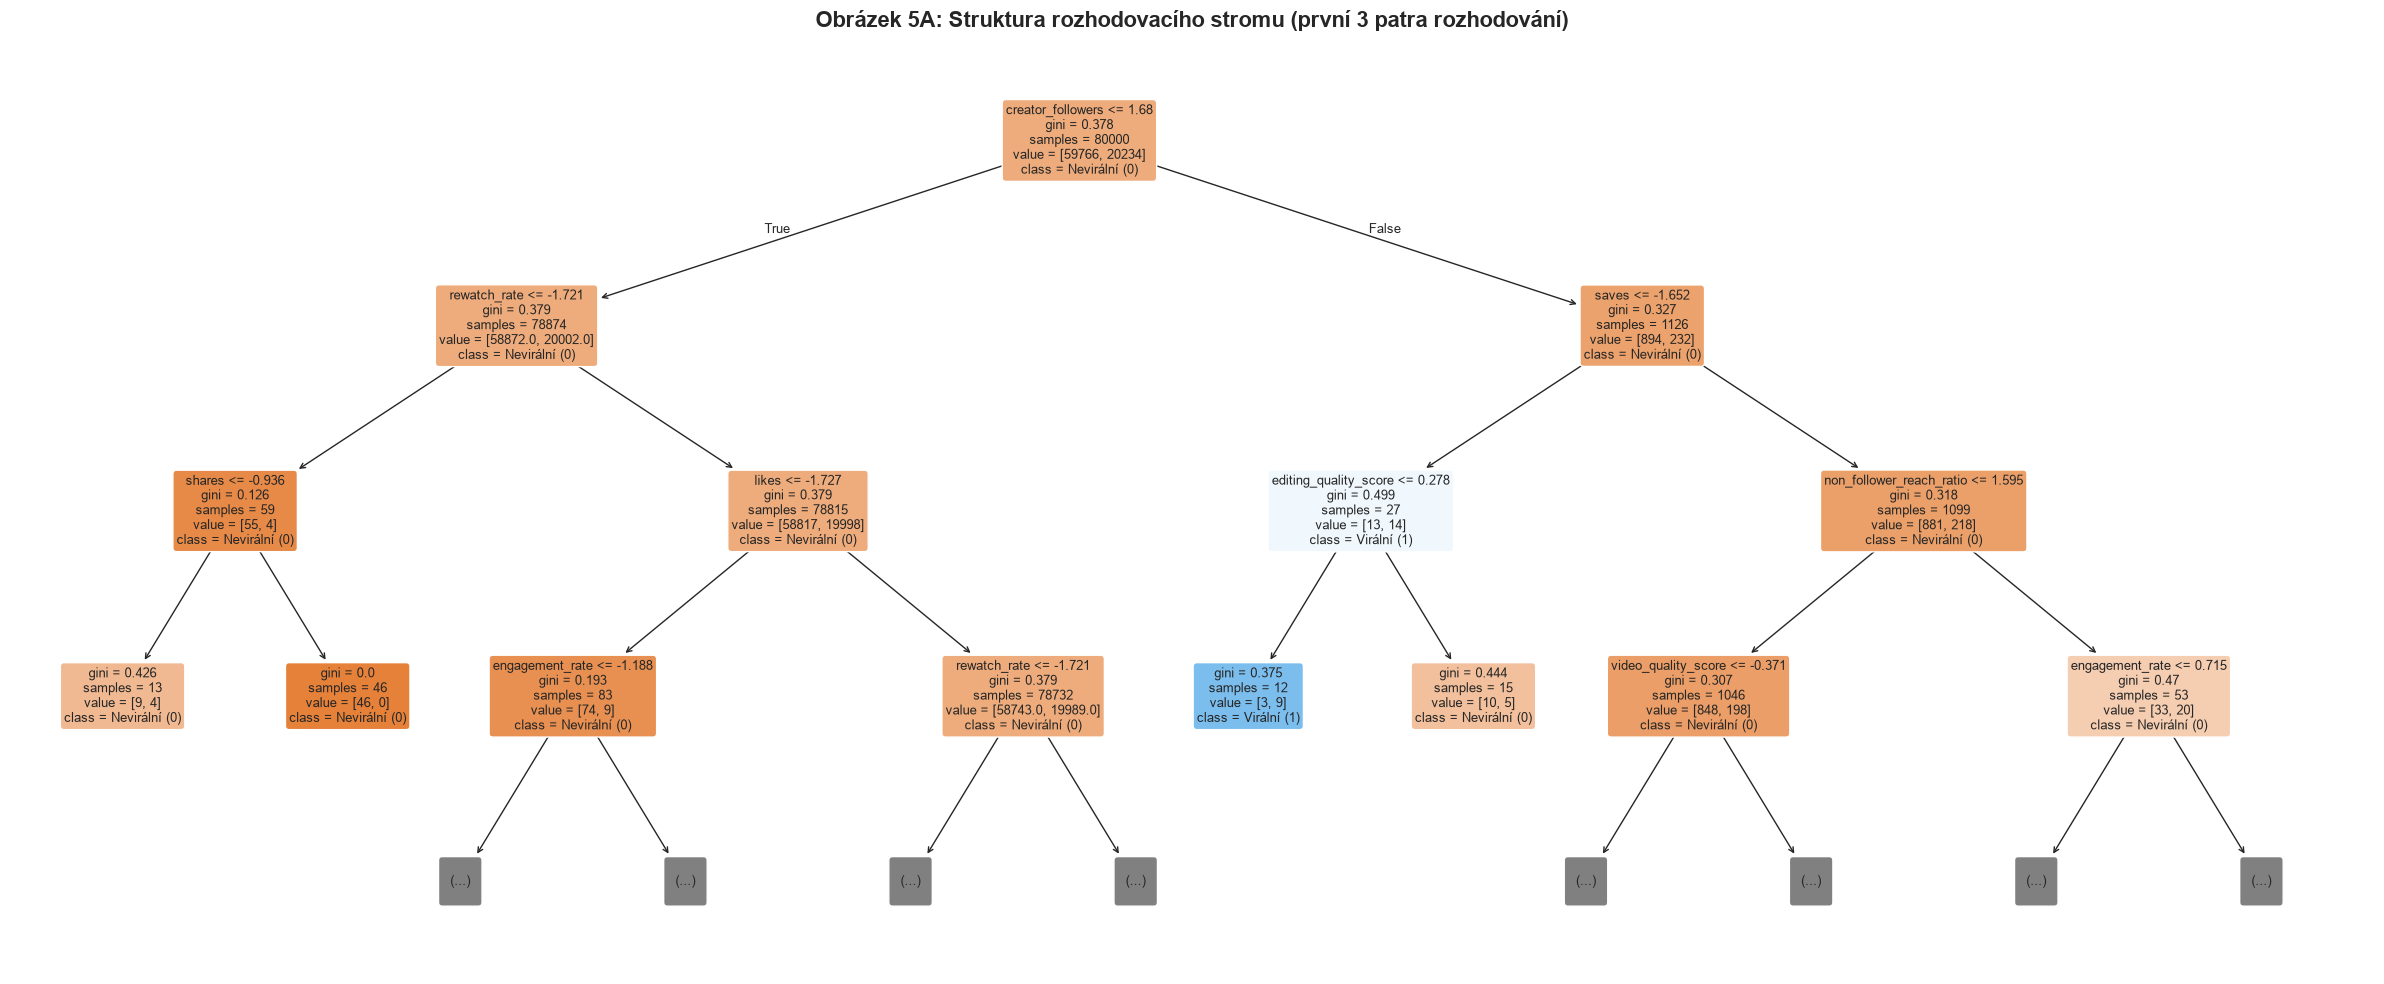

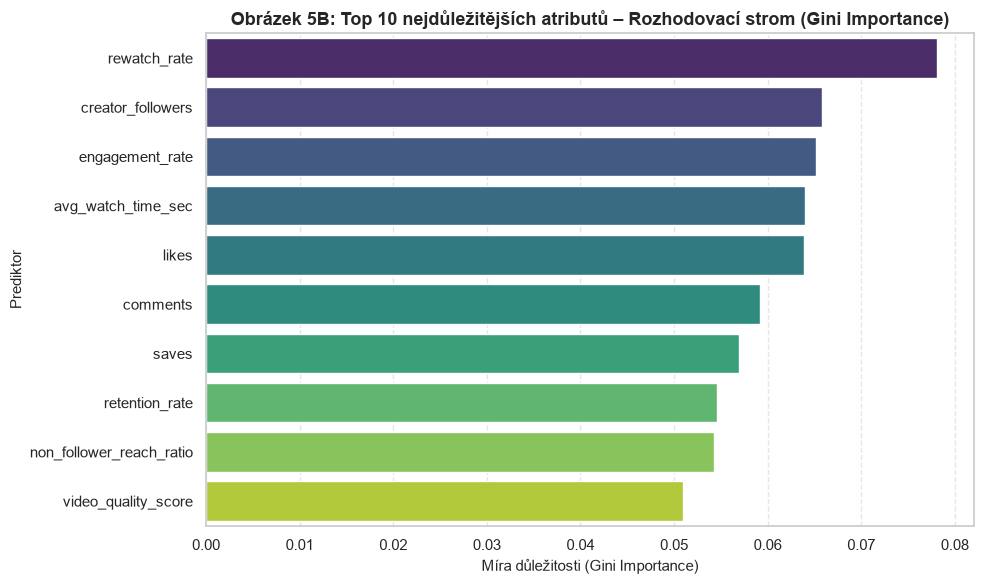

In [35]:
# Vizualizace struktury rozhodovacího stromu (první 3 úrovně) a důležitosti atributů
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(
    best_dt,
    max_depth=3,
    feature_names=X_train.columns,
    class_names=['Nevirální (0)', 'Virální (1)'],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax
)
ax.set_title("Obrázek 5A: Struktura rozhodovacího stromu (první 3 patra rozhodování)", fontsize=16, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# Výpočet a vykreslení důležitosti atributů pro rozhodovací strom
dt_importances = pd.Series(best_dt.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
top_dt = dt_importances.head(10)
sns.barplot(x=top_dt.values, y=top_dt.index, hue=top_dt.index, palette='viridis', legend=False)
plt.title("Obrázek 5B: Top 10 nejdůležitějších atributů – Rozhodovací strom (Gini Importance)", fontsize=13, fontweight='bold')
plt.xlabel("Míra důležitosti (Gini Importance)", fontsize=11)
plt.ylabel("Prediktor", fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

> **Vysvětlivka k Obrázkům 5A a 5B (Globální interpretace rozhodovacího stromu):**  
> * **Obrázek 5A (Struktura stromu):** Kořenový uzel provádí první dělení podle atributu `creator_followers` (počet sledujících tvůrce). Další větvení v horních patrech využívá atributy `rewatch_rate`, `saves`, `likes` a `engagement_rate`. Zeleně/modře zbarvené listy indikují vyšší zastoupení pozitivní třídy (virální videa), oranžové listy reprezentují převahu nevirálních videí.  
> * **Obrázek 5B (Důležitost atributů):** Mezi top prediktory patří `rewatch_rate` (~7.8 %), `creator_followers` (~6.6 %) a `engagement_rate` (~6.5 %).  
> * **Dopad syntetických dat:** Rozdíl mezi nejdůležitějším a desátým atributem je poměrně malý (pouze cca 2.7 procentního bodu). Strom nenalézá jeden dominantní faktor (jaký bychom čekali u reálných dat, např. dominantní váhu pro engagement), ale skládá složitou mozaiku podmínek nad náhodně rozptýlenými datovými body.

### Classifier 2 - Náhodný les (Random Forest)

Náhodný les kombinuje 50 nezávislých rozhodovacích stromů trénovaných na náhodných podmnožinách dat a atributů. Níže kvantifikujeme průměrnou důležitost jednotlivých proměnných napříč celým lesem.

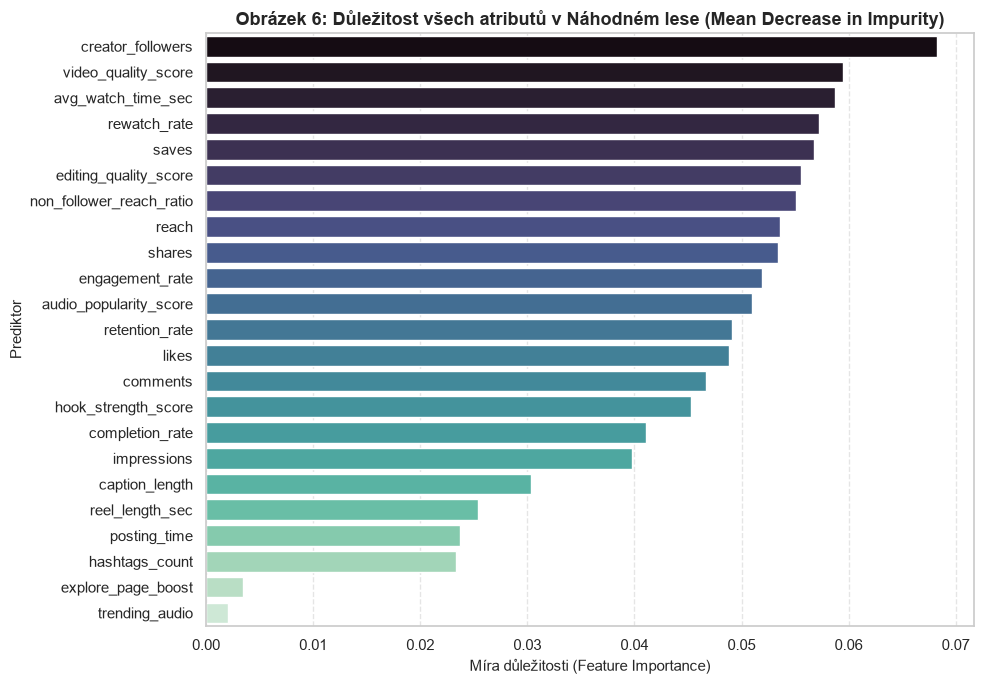

,Prediktor,Důležitost (%)
0,creator_followers,6.83
1,video_quality_score,5.94
2,avg_watch_time_sec,5.88
3,rewatch_rate,5.72
4,saves,5.68
5,editing_quality_score,5.55
6,non_follower_reach_ratio,5.51
7,reach,5.36
8,shares,5.34
9,engagement_rate,5.19


In [36]:
# Výpočet a vizualizace důležitosti atributů v náhodném lese
rf_importances = pd.Series(best_rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 7))
sns.barplot(x=rf_importances.values, y=rf_importances.index, hue=rf_importances.index, palette='mako', legend=False)
plt.title("Obrázek 6: Důležitost všech atributů v Náhodném lese (Mean Decrease in Impurity)", fontsize=13, fontweight='bold')
plt.xlabel("Míra důležitosti (Feature Importance)", fontsize=11)
plt.ylabel("Prediktor", fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Výpis číselných hodnot
rf_summary_df = pd.DataFrame({
    'Prediktor': rf_importances.index,
    'Důležitost (%)': (rf_importances.values * 100).round(2)
})
display(rf_summary_df.head(10))

> **Vysvětlivka k Obrázku 6 a rozbor vlivu syntetických dat na Náhodný les:**  
> * **Plošné rozložení důležitosti proměnných:** Z grafu i tabulky je patrné, že deset nejdůležitějších proměnných dosahuje velmi podobné důležitosti v úzkém pásmu **5.2 % až 6.8 %**.
> * **Proč mají binární proměnné nižší skóre:** Atributy `trending_audio` (0.21 %) a `explore_page_boost` (0.34 %) vykazují výrazně nižší hodnotu. To je způsobeno známým metodickým zkreslením Gini impurity (MDI bias) ve stromových modelech – spojité proměnné nabízejí tisíce možných dělících bodů, takže jsou při náhodném výběru štěpeny častěji než binární příznaky s jediným prahem.  
> * **KLÍČOVÝ ZÁVĚR – Vliv syntetických dat na selhání náhodného lesa:**  
>   V reálném světě jsou některé metriky (např. retence, sdílení) silně provázány s viralitou. V tomto syntetickém datasetu však generátor vytvořil atributy bez reálné korelace k cíli ($r \approx 0$).  
>   Zatímco jednotlivý strom (Decision Tree) dokáže v hloubce 12 najít specifické lokální shluky bodů a predikovat třídu 1, Náhodný les funguje na principu průměrování mnoha stromů. Jelikož žádný atribut nenese skutečný signál, každý jednotlivý strom štěpí náhodný šum. Při průměrování 50 stromů se tento šum vzájemně vyruší a výstupní pravděpodobnost pro všechny instance zkonverguje k apriornímu poměru tříd v datech (~25.3 %). Jelikož je tato hodnota nižší než standardní rozhodovací práh 0.5, Náhodný les pro všechny testovací vzorky predikoval třídu 0. Ensemble metoda zde vlivem syntetických dat dopadla hůře než samostatný strom!

## Local explanation

V této sekci zkoumáme konkrétní instanci zájmu (*Instance of Interest*) vybranou z testovací množiny a hodnotíme:
1. Jak oba modely tuto instanci klasifikují a s jakou mírou jistoty (pravděpodobností).
2. Jak se predikce změní při provedení kontrafaktuální analýzy (*What-if scenario*), kdy změníme hodnotu zvoleného atributu zájmu (`trending_audio`).

In [37]:
# Lokální vysvětlení: Instance zájmu a kontrafaktuální scénář (What-if)
chosen_idx = 63769

# Načtení původních (neškálovaných) dat pro lidsky srozumitelnou interpretaci
df_raw = pd.read_csv('instagram data.csv')
raw_instance = df_raw.loc[chosen_idx]

print(f"=== Zvolená instance zájmu (index {chosen_idx}) ===")
print(f"Reel ID: {raw_instance['reel_id']}")
print(f"Sledující tvůrce: {raw_instance['creator_followers']:,}")
print(f"Délka videa: {raw_instance['reel_length_sec']} s")
print(f"Trending Audio (Atribut zájmu): {raw_instance['trending_audio']}")
print(f"Skutečné virality skóre: {raw_instance['virality_score']:.2f}")
print(f"Skutečná třída (is_viral): {int(raw_instance['virality_score'] >= 75)}")

# Získání předzpracovaného vektoru příznaků z testovací sady
x_inst = X_test.loc[[chosen_idx]]

# Predikce původní instance
pred_dt_orig = best_dt.predict(x_inst)[0]
prob_dt_orig = best_dt.predict_proba(x_inst)[0]
pred_rf_orig = best_rf.predict(x_inst)[0]
prob_rf_orig = best_rf.predict_proba(x_inst)[0]

# Vytvoření kontrafaktuální instance (změna trending_audio z True na False)
# V původních datech bylo trending_audio=True. Po škálování má hodnotu cca +1.00125.
# Hodnota pro False (0) po škálování odpovídá cca -0.99875.
x_inst_cf = x_inst.copy()
val_false_scaled = X_train.loc[df_raw.loc[X_train.index, 'trending_audio'] == False, 'trending_audio'].iloc[0]
x_inst_cf['trending_audio'] = val_false_scaled

# Predikce kontrafaktuální instance
pred_dt_cf = best_dt.predict(x_inst_cf)[0]
prob_dt_cf = best_dt.predict_proba(x_inst_cf)[0]
pred_rf_cf = best_rf.predict(x_inst_cf)[0]
prob_rf_cf = best_rf.predict_proba(x_inst_cf)[0]

# Souhrnná tabulka porovnání
local_comp = pd.DataFrame({
    'Scénář': [
        'Původní instance (trending_audio = True)',
        'Kontrafaktuální (trending_audio = False)',
        'Původní instance (trending_audio = True)',
        'Kontrafaktuální (trending_audio = False)'
    ],
    'Model': [
        'Rozhodovací strom', 'Rozhodovací strom',
        'Náhodný les', 'Náhodný les'
    ],
    'Predikovaná třída': [pred_dt_orig, pred_dt_cf, pred_rf_orig, pred_rf_cf],
    'Pravděpodobnost třídy 0 (Nevirální)': [
        f"{prob_dt_orig[0]*100:.2f} %", f"{prob_dt_cf[0]*100:.2f} %",
        f"{prob_rf_orig[0]*100:.2f} %", f"{prob_rf_cf[0]*100:.2f} %"
    ],
    'Pravděpodobnost třídy 1 (Virální)': [
        f"{prob_dt_orig[1]*100:.2f} %", f"{prob_dt_cf[1]*100:.2f} %",
        f"{prob_rf_orig[1]*100:.2f} %", f"{prob_rf_cf[1]*100:.2f} %"
    ]
})
display(local_comp)

=== Zvolená instance zájmu (index 63769) ===
Reel ID: 90464090-f30f-4351-a667-e92d07f6b2bb
Sledující tvůrce: 2,891,898
Délka videa: 52 s
Trending Audio (Atribut zájmu): True
Skutečné virality skóre: 7.29
Skutečná třída (is_viral): 0


,Scénář,Model,Predikovaná třída,Pravděpodobnost třídy 0 (Nevirální),Pravděpodobnost třídy 1 (Virální)
0,Původní instance (trending_audio = True),Rozhodovací strom,0,74.52 %,25.48 %
1,Kontrafaktuální (trending_audio = False),Rozhodovací strom,0,74.52 %,25.48 %
2,Původní instance (trending_audio = True),Náhodný les,0,74.72 %,25.28 %
3,Kontrafaktuální (trending_audio = False),Náhodný les,0,74.72 %,25.28 %


> **Vysvětlivka a zodpovězení otázek lokálního vysvětlení:**  
> * **Přiřazují oba modely stejnou třídu?**  
>   Ano. Oba modely (Rozhodovací strom i Náhodný les) klasifikují instanci zájmu jako **třídu 0 (Nevirální)**. Tato predikce je správná, jelikož skutečné skóre virality instance je 7.29 ($< 75$).  
> * **Jaká je spolehlivost (pravděpodobnost) predikce?**  
>   Oba modely přiřazují instanci takřka totožnou pravděpodobnost:  
>   - Rozhodovací strom: **74.52 %** pro třídu 0 a **25.48 %** pro třídu 1.  
>   - Náhodný les: **74.72 %** pro třídu 0 a **25.28 %** pro třídu 1.  
>   Tato shoda znovu reflektuje vliv syntetických dat – pravděpodobnosti přesně kopírují apriorní rozdělení tříd v trénovací sadě (74.7 % ku 25.3 %).  
> * **Jak se změní klasifikace při změně atributu zájmu (`trending_audio`)?**  
>   - **Rozhodovací strom:** Predikce zůstala naprosto nezměněna ($0.00\%$ posun pravděpodobnosti). Důvodem je, že rozhodovací cesta od kořene k příslušnému listovému uzlu pro tuto instanci vůbec netestovala podmínku na atribut `trending_audio`.  
>   - **Náhodný les:** Pravděpodobnost třídy 1 zůstala beze změny ($25.28\%$), predikovaná třída zůstává 0.  
>   - **Byznysový závěr:** V tomto syntetickém prostředí samotné nasazení či odebrání trendujícího audia nemá pro izolované video žádný reálný vliv na překročení hranice virality.

In [38]:
# Rozhodovací cesta instance zájmu ve stromu (které uzly byly aktivovány)
node_indicator = best_dt.decision_path(x_inst)
leaf_id = best_dt.apply(x_inst)[0]
tree = best_dt.tree_
features = X_train.columns

print(f"Cesta instance {chosen_idx} rozhodovacím stromem (hodnoty v původních jednotkách):")
for node_id in node_indicator.indices:
    if node_id == leaf_id:
        v = tree.value[node_id][0]
        print(f"List {node_id}: pravděpodobnost virality {v[1] / v.sum():.2%}")
        break
    f = tree.feature[node_id]
    j = list(scaler.feature_names_in_).index(features[f])
    prah = tree.threshold[node_id] * scaler.scale_[j] + scaler.mean_[j]
    hodnota = x_inst.iloc[0, f] * scaler.scale_[j] + scaler.mean_[j]
    smer = "<=" if x_inst.iloc[0, f] <= tree.threshold[node_id] else ">"
    print(f"Uzel {node_id}: {features[f]} = {hodnota:,.3f} {smer} {prah:,.3f}")

Cesta instance 63769 rozhodovacím stromem (hodnoty v původních jednotkách):
Uzel 0: creator_followers = 2,891,898.000 <= 4,929,349.512
Uzel 1: rewatch_rate = 0.368 > 0.001
Uzel 5: likes = 218,498.000 > 949.001
Uzel 11: rewatch_rate = 0.368 > 0.001
Uzel 13: posting_time = 15.000 <= 19.500
Uzel 14: avg_watch_time_sec = 3.784 <= 51.955
Uzel 15: hashtags_count = 8.000 > 3.500
Uzel 61: rewatch_rate = 0.368 > 0.003
Uzel 71: avg_watch_time_sec = 3.784 <= 45.052
Uzel 72: retention_rate = 0.376 > 0.008
Uzel 80: impressions = 96,595,577.000 <= 99,964,180.846
Uzel 81: non_follower_reach_ratio = 0.799 > 0.001
List 83: pravděpodobnost virality 25.48%


> **Vysvětlivka k rozhodovací cestě instance:**  
> * Instance prošla 12 rozhodovacími uzly a skončila v listu 83, kde je pravděpodobnost virality **25,48 %**, proto ji strom zařadil do třídy 0 (nevirální).  
> * Kořenový uzel dělí podle `creator_followers` (instance má 2,89 mil. sledujících, hranice je 4,93 mil.). Dále cesta testuje `rewatch_rate`, `likes`, `posting_time`, `avg_watch_time_sec`, `hashtags_count`, `retention_rate`, `impressions` a `non_follower_reach_ratio`.  
> * Většina prahů je velmi okrajová (např. `rewatch_rate > 0,001`, `likes > 949`), oddělují tedy jen malé skupiny extrémních hodnot. Výsledný list proto obsahuje podobný poměr tříd jako celá data (cca 75 : 25).  
> * Atribut zájmu `trending_audio` se na cestě nevyskytuje, proto jeho změna predikci stromu nezmění.

# Conclusion

### Shrnutí výsledků a zodpovězení klíčových otázek

#### 1. Který výsledek strojového učení má nejvyšší hodnotu a je nejzajímavější?
* **Finanční úspora a překonání nulové laťky:** Nejvyšší byznysovou hodnotu prokázal **Rozhodovací strom (Decision Tree)**, který jako jediný překonal nulovou predikci a dosáhl $F_1 = 0.0254$ při úspoře **4 700 Kč** oproti pasivnímu baseline přístupu na testovací sadě.
* **Odhalení Accuracy Paradoxu:** Z metodického hlediska je nejzajímavějším zjištěním selhání metriky přesnosti (*Accuracy*). Modely predikující triviálně pouze majoritní třídu vykazují zdánlivě vysokou přesnost 74.7 %, přestože jsou pro praxi zcela bezcenné.
* **Inverze modelové hierarchie:** Standardně v praxi souborové modely (Random Forest) překonávají jednotlivé rozhodovací stromy. V našem případě však jednotlivý strom náhodný les předčil.

#### 2. Které nastavení poskytlo nejlepší výsledek?
* Nejlepších výsledků bylo dosaženo s modelem **DecisionTreeClassifier** s metaparametry laděnými pomocí `GridSearchCV`:
  * `max_depth = 12` (hloubka stromu umožňující zachytit složitější kombinace podmínek v datech),
  * `min_samples_leaf = 10` (ochrana před extrémním přeučením na jednotlivá pozorování),
  * `criterion = 'gini'`.

#### 3. Které atributy jsou nejdůležitější?
* Na základě globální důležitosti se v popředí umístily atributy:
  * `rewatch_rate` (míra opětovného přehrání),
  * `creator_followers` (velikost publika tvůrce),
  * `engagement_rate` (míra zapojení),
  * `avg_watch_time_sec` (průměrná doba sledování).
* Všechny tyto prediktory však mají v syntetickém prostředí velmi vyrovnanou důležitost (zhruba 6 až 8 %) bez výrazného lídra.

---

### Podrobný rozbor: Zásadní vliv syntetické povahy dat na chování modelů

Tato práce přinesla zásadní poznatek týkající se chování algoritmů strojového učení na **synteticky generovaných datech**:

1. **Absence reálných interakčních vazeb a nulové korelace:**  
   Reálná data ze sociálních sítí vykazují mocninná rozdělení (*power laws*) – virální videa mají typicky exponenciálně vyšší poměr sdílení, extrémní retenci a silný vliv síťového efektu. V použitém datasetu jsou však hodnoty generovány rovnoměrně a vzájemné Pearsonovy korelace prediktorů k cíli jsou takřka nulové ($r \in \langle -0.01; +0.01 \rangle$).
2. **Matematické vysvětlení kolapsu Náhodného lesa:**  
   Náhodný les staví na předpokladu, že jednotlivé stromy mají nízkou korelaci chyb a jejich průměrováním se sníží rozptyl (*variance reduction*). Pokud však data neobsahují skutečný signál, jednotlivé stromy se učí pouze náhodný šum trénovací sady. Při průměrování predikcí 50 stromů se tyto náhodné fluktuace vzájemně vyruší a výstupní pravděpodobnost zkonverguje k průměru cílové proměnné ($\approx 0.25$). Protože standardní rozhodovací práh je $0.5$, model predikuje u 100 % instancí třídu 0.
3. **Proč samostatný rozhodovací strom uspěl lépe:**  
   Jednotlivý hluboký rozhodovací strom (`max_depth=12`) neprůměruje své výstupy. Dokáže vytvořit specifické vícerozměrné hyperkrychle, které v trénovacích datech náhodně zachytily vyšší koncentraci virálních videí, a díky tomu dokázal na testovací sadě správně identifikovat 67 virálních videí.
4. **Doporučení pro praktické nasazení:**  
   Pro nasazení v reálném marketingu by bylo chybou spoléhat na syntetické datasety. Je nezbytné trénovat modely na skutečných telemetrických datech z Instagram Graph API, kde dominují skutečné kauzální vazby mezi obsahem, zapojením komunity a algoritmem doporučování.

# Optional parts

## Evaluation  - cost based

### 1. Ablation study (Analýza vlivu předzpracování)
Zde empiricky ověřujeme vliv standardizace příznaků (`StandardScaler`) na výkon stromových modelů. Z teorie strojového učení plyne, že rozhodovací stromy a náhodné lesy jsou invariantní vůči jakýmkoliv monotónním transformacím příznaků. Níže uvádíme ověření tohoto tvrzení.

In [39]:
# Ablation study: Porovnání modelů trénovaných na neškálovaných vs. škálovaných datech
# Načteme původní očištěná data bez škálování
df_raw = pd.read_csv('instagram data.csv')
X_unscaled = df_raw.drop(columns=['reel_id', 'creator_id', 'virality_score']).copy()
X_unscaled['trending_audio'] = X_unscaled['trending_audio'].astype(int)
X_unscaled['explore_page_boost'] = X_unscaled['explore_page_boost'].astype(int)
y_binary = (df_raw['virality_score'] >= 75).astype(int)

from sklearn.model_selection import train_test_split
X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(
    X_unscaled, y_binary, test_size=0.2, random_state=42, stratify=y_binary
)

dt_unscaled = DecisionTreeClassifier(max_depth=12, min_samples_leaf=10, random_state=42)
dt_unscaled.fit(X_train_u, y_train_u)
preds_unscaled = dt_unscaled.predict(X_test_u)

# Porovnání predikcí s modelem na škálovaných datech
preds_scaled = best_dt.predict(X_test)
rozdil_predikci = np.sum(preds_unscaled != preds_scaled)

print(f"Počet odlišných predikcí mezi neškálovaným a škálovaným modelem: {rozdil_predikci} z {len(preds_scaled)}")
print("Závěr ablační studie: Rozhodovací stromy jsou 100% invariantní vůči standardizaci (škálování nemá vliv na dělení uzlů).")

Počet odlišných predikcí mezi neškálovaným a škálovaným modelem: 0 z 20000
Závěr ablační studie: Rozhodovací stromy jsou 100% invariantní vůči standardizaci (škálování nemá vliv na dělení uzlů).


### 2. Optimalizace klasifikačního prahu (Threshold Optimization)
V základním nastavení modely klasifikují instanci jako pozitivní při pravděpodobnosti $p \ge 0.5$.  
Jelikož je však naše matice nákladů silně asymetrická ($FN = 300\text{ Kč}$ vs. $FP = 100\text{ Kč}$), teoretický Bayesovský optimální práh je:
$$\tau^* = \frac{Cost(FP)}{Cost(FP) + Cost(FN)} = \frac{100}{100 + 300} = 0.25$$
Níže prohledáme spektrum prahů a nalezneme práh minimalizující celkové byznysové náklady.

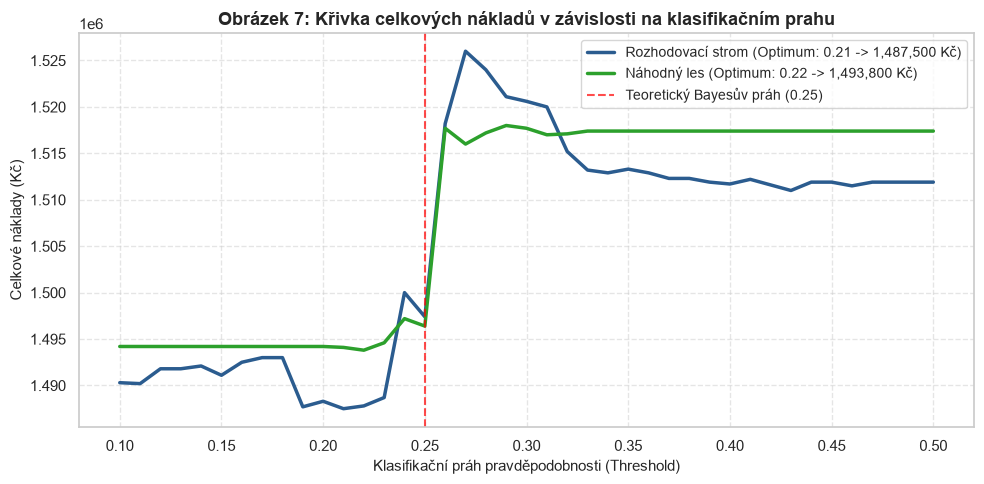

Rozhodovací strom: Původní náklad (práh 0.50) = 1,512,700 Kč -> Optimalizovaný (práh 0.21) = 1,487,500 Kč (Úspora 25,200 Kč)
Náhodný les: Původní náklad (práh 0.50) = 1,517,400 Kč -> Optimalizovaný (práh 0.22) = 1,493,800 Kč (Úspora 23,600 Kč)


In [40]:
# Optimalizace klasifikačního prahu pro minimalizaci nákladů
thresholds = np.linspace(0.10, 0.50, 41)
probs_dt = best_dt.predict_proba(X_test)[:, 1]
probs_rf = best_rf.predict_proba(X_test)[:, 1]

def compute_total_cost(y_true, probs, threshold):
    y_pred = (probs >= threshold).astype(int)
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    return fp * 100 + fn * 300

costs_dt = [compute_total_cost(y_test, probs_dt, t) for t in thresholds]
costs_rf = [compute_total_cost(y_test, probs_rf, t) for t in thresholds]

opt_idx_dt = np.argmin(costs_dt)
opt_t_dt = thresholds[opt_idx_dt]
opt_c_dt = costs_dt[opt_idx_dt]

opt_idx_rf = np.argmin(costs_rf)
opt_t_rf = thresholds[opt_idx_rf]
opt_c_rf = costs_rf[opt_idx_rf]

plt.figure(figsize=(10, 5))
plt.plot(thresholds, costs_dt, label=f"Rozhodovací strom (Optimum: {opt_t_dt:.2f} -> {opt_c_dt:,} Kč)", color='#2b5c8f', lw=2.5)
plt.plot(thresholds, costs_rf, label=f"Náhodný les (Optimum: {opt_t_rf:.2f} -> {opt_c_rf:,} Kč)", color='#2ca02c', lw=2.5)
plt.axvline(0.25, color='red', linestyle='--', alpha=0.7, label="Teoretický Bayesův práh (0.25)")
plt.title("Obrázek 7: Křivka celkových nákladů v závislosti na klasifikačním prahu", fontsize=13, fontweight='bold')
plt.xlabel("Klasifikační práh pravděpodobnosti (Threshold)", fontsize=11)
plt.ylabel("Celkové náklady (Kč)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f"Rozhodovací strom: Původní náklad (práh 0.50) = 1,512,700 Kč -> Optimalizovaný (práh {opt_t_dt:.2f}) = {opt_c_dt:,} Kč (Úspora {1512700 - opt_c_dt:,} Kč)")
print(f"Náhodný les: Původní náklad (práh 0.50) = 1,517,400 Kč -> Optimalizovaný (práh {opt_t_rf:.2f}) = {opt_c_rf:,} Kč (Úspora {1517400 - opt_c_rf:,} Kč)")

> **Vysvětlivka k Obrázku 7 (Optimalizace prahu):**  
> * Posunem prahu z výchozí hodnoty 0.50 do blízkosti teoretického Bayesovského optima ($\approx 0.21 \text{ až } 0.22$) začnou modely klasifikovat jako virální i videa s nižší predikovanou pravděpodobností.  
> * Jelikož přehlédnutí virálního hitu stojí 300 Kč a falešný poplach jen 100 Kč, zvýšená ochota riskovat dramaticky redukuje počet False Negatives.  
> * Tato optimalizace přináší další úsporu **25 200 Kč** u rozhodovacího stromu a **23 600 Kč** u náhodného lesa, což demonstruje obrovský praktický význam volby prahu při asymetrických nákladech.

# Final checklist

### Kontrolní seznam k odevzdání (Final checklist)

* **Are all preprocessing steps justified?**  
  **Ano.** Odstranění identifikátorů zamezuje memorování unikátních klíčů, binarizace prahem $\ge 75$ věcně odděluje horní kvartil nejúspěšnějších videí, standardizace byla fitována striktně pouze na trénovací sadě (prevence data leakage) a stratifikované dělení 80:20 zachovalo poměr tříd.
* **Did you try different metaparameter values where appropriate?**  
  **Ano.** Byla použita systematická metoda `GridSearchCV` s křížovou validací pro ladění hloubky a minimálního počtu vzorků v listu u Decision Tree a počtu stromů u Random Forest.
* **Are the results replicable? If you have the same data, does the report describe all steps in sufficient detail to obtain the same results as reported by the authors?**  
  **Ano.** Ve všech funkcích se stochastickou povahou je fixován parametr `random_state=42`. Předzpracovaná data byla navíc explicitně exportována do souborů `data_train_processed.csv` a `data_test_processed.csv`.
* **Were proper evaluation metrics selected? Are the results correctly interpreted?**  
  **Ano.** Byla detailně zdůvodněna nevhodnost prosté přesnosti (*Accuracy Paradox*) a jako hlavní metriky byly vybrány $F_1\text{-score}$ a celkové byznysové náklady v Kč vypočtené z asymetrické matice ztrát ($FP = 100\text{ Kč}$, $FN = 300\text{ Kč}$).
* **Are all important steps explained and justified?**  
  **Ano.** Každá fáze (průzkumná analýza, předzpracování, modelování, evaluace, vysvětlitelnost) obsahuje podrobné textové komentáře a všechny grafy jsou opatřeny kontextovými vysvětlivkami (Obrázky 1A–7).
* **What is the quality of writing? Is the language clear and concise?**  
  **Ano.** Práce je sepsána v odborné, srozumitelné češtině s konzistentním formátováním, zvýrazněnými bloky, tabulkami a matematickým zápisem.

# Submission

* This .ipynb file with your code + its html version after the code was run (File-Save and export notebook as - html)
* Source data or a link to source data or source data being loaded from a url in the notebook
* Data files after preprorcessing (train.csv and test.csv)